> ⚠️ **AVISO METODOLÓGICO** — leia antes de continuar.
>
> Este notebook reporta **100% perfeito no Estágio 2 (COPD vs URTI)** após aplicar SMOTE. Esse resultado foi **invalidado** pelo notebook 14, que repetiu a análise sem SMOTE e com undersampling rigoroso, obtendo recall URTI realista de ~0,51.
>
> **Causa do leakage:** SMOTE interpola no espaço de features que, mesmo após residualização linear, ainda preserva variância sutilmente correlacionada com equipamento. O nb15 confirma que a residualização reduz o probe-equipamento em 89,7%, mas não a zero.
>
> **Este notebook é mantido como contra-exemplo metodológico** — exemplo honesto de quando um número 'bonito' deve ser questionado.

---

# 13 — Classificador hierárquico + SMOTE + recall como métrica principal

**Nova abordagem metodológica baseada em 4 princípios clínicos:**

1. **Recall doente como métrica principal** — em medicina, perder doente (FN) é muito mais grave que tratar saudável (FP). F1-macro vira métrica secundária.

2. **Mais avaliação no teste** — `RepeatedStratifiedGroupKFold` 5×5 = **25 folds externos**, muito mais robusto que holdout único (21 pacientes).

3. **Classificador hierárquico em 2 estágios:**
   - **Estágio 1 (binário):** Saudável vs Doente — maximizar recall doente
   - **Estágio 2 (binário):** dentro dos doentes, COPD vs URTI
   - **Vantagem:** cada estágio é problema mais simples (binário) com objetivo claro

4. **Balanceamento via SMOTE** — Synthetic Minority Over-sampling. Gera amostras sintéticas da classe minoritária no espaço de features. Aplicado **só no treino de cada fold** (não vaza).

In [1]:
import sys, time, warnings
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, LabelEncoder, OneHotEncoder
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (recall_score, precision_score, f1_score,
                              accuracy_score, confusion_matrix,
                              classification_report, roc_curve, auc)
from imblearn.over_sampling import SMOTE

from src import config
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

## 1. Carregar dados e definir alvos

In [2]:
feats_df = pd.read_csv(config.PROCESSED_DIR / 'features.csv')
FEATURE_COLS = [c for c in feats_df.columns
                if c not in ('filename','patient_id','equipment',
                             'chest_location','label_multi','label_binary')]
X = feats_df[FEATURE_COLS].values
groups = feats_df['patient_id'].values
equipment = feats_df['equipment'].values
EQUIPMENT_CATS = sorted(set(equipment))

# Alvo binário Estágio 1: doente (COPD ou URTI) = 1, saudável = 0
y_bin = (feats_df['label_multi'] != 'Healthy').astype(int).values

# Alvo binário Estágio 2: dentro dos doentes — COPD = 0, URTI = 1
mask_disease = feats_df['label_multi'] != 'Healthy'
y_sub = (feats_df.loc[mask_disease, 'label_multi'] == 'URTI').astype(int).values

# Alvo multiclasse (para comparação)
le_multi = LabelEncoder()
y_multi = le_multi.fit_transform(feats_df['label_multi'])
CLASSES = list(le_multi.classes_)

print(f'Total amostras: {len(X)} | features: {X.shape[1]} | pacientes: {len(np.unique(groups))}')
print()
print('Estágio 1 — Saudável (0) vs Doente (1):')
print(f'  Saudável: {(y_bin==0).sum()} grav. | Doente: {(y_bin==1).sum()} grav. | razão {(y_bin==1).sum()/(y_bin==0).sum():.1f}×')
print()
print('Estágio 2 — COPD (0) vs URTI (1) [só doentes]:')
print(f'  COPD: {(y_sub==0).sum()} grav. | URTI: {(y_sub==1).sum()} grav. | razão {(y_sub==0).sum()/(y_sub==1).sum():.1f}×')

Total amostras: 851 | features: 78 | pacientes: 104

Estágio 1 — Saudável (0) vs Doente (1):
  Saudável: 35 grav. | Doente: 816 grav. | razão 23.3×

Estágio 2 — COPD (0) vs URTI (1) [só doentes]:
  COPD: 793 grav. | URTI: 23 grav. | razão 34.5×


## 2. Funções utilitárias

Pipeline (residualizar → scale → SMOTE → LogReg) aplicado **dentro de cada fold de treino**.
SMOTE só atua no treino — nunca toca no teste.

In [3]:
def fit_residualizer(X_tr, eq_tr):
    ohe = OneHotEncoder(sparse_output=False, categories=[EQUIPMENT_CATS])
    E_tr = ohe.fit_transform(eq_tr.reshape(-1, 1))
    lr = LinearRegression().fit(E_tr, X_tr)
    return ohe, lr

def residualize(X, eq, ohe, lr):
    E = ohe.transform(eq.reshape(-1, 1))
    return X - lr.predict(E)

def train_pipeline_smote(X_tr, y_tr, eq_tr, apply_smote=True, smote_random_state=0):
    """Treina o pipeline completo num fold. Retorna objetos necessários para predict."""
    ohe, lr_res = fit_residualizer(X_tr, eq_tr)
    Xr_tr = residualize(X_tr, eq_tr, ohe, lr_res)
    sc = StandardScaler().fit(Xr_tr)
    Xs_tr = sc.transform(Xr_tr)
    if apply_smote and len(np.unique(y_tr)) > 1:
        # Determinar k_neighbors válido (deve ser < n da classe minoritária)
        n_min = min(np.bincount(y_tr))
        k = min(5, max(1, n_min - 1))
        smote = SMOTE(random_state=smote_random_state, k_neighbors=k)
        Xs_tr, y_tr = smote.fit_resample(Xs_tr, y_tr)
    clf = LogisticRegression(max_iter=3000, class_weight='balanced').fit(Xs_tr, y_tr)
    return {'ohe': ohe, 'lr_res': lr_res, 'sc': sc, 'clf': clf}

def predict_pipeline(pipe, X_te, eq_te):
    Xr = residualize(X_te, eq_te, pipe['ohe'], pipe['lr_res'])
    Xs = pipe['sc'].transform(Xr)
    return pipe['clf'].predict(Xs), pipe['clf'].predict_proba(Xs)

def patient_metrics(y_true, y_pred, groups):
    d = pd.DataFrame({'g': groups, 'y': y_true, 'p': y_pred})
    a = d.groupby('g').agg(y=('y', 'first'),
                            p=('p', lambda s: s.value_counts().idxmax()))
    return a['y'].values, a['p'].values

print('Funções utilitárias prontas.')

Funções utilitárias prontas.


## 3. Estágio 1 — Classificador binário Healthy vs Disease

**Métrica principal: Recall(Disease).** Queremos detectar TODOS os doentes; saudáveis marcados como doentes apenas geram consulta extra.

Repeated 5×5-fold = 25 folds externos.

In [4]:
N_REPEATS = 5
N_SPLITS = 5

rows_stage1 = []
y_pred_all_stage1 = np.zeros(len(X))
y_proba_all_stage1 = np.zeros(len(X))
t0 = time.time()

for rep in range(N_REPEATS):
    cv = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=42+rep)
    for fold, (tr, te) in enumerate(cv.split(X, y_bin, groups)):
        # --- sem SMOTE ---
        pipe_nosm = train_pipeline_smote(X[tr], y_bin[tr], equipment[tr], apply_smote=False)
        y_pred_no, y_proba_no = predict_pipeline(pipe_nosm, X[te], equipment[te])
        # --- com SMOTE ---
        pipe_sm = train_pipeline_smote(X[tr], y_bin[tr], equipment[tr], apply_smote=True,
                                        smote_random_state=42+rep)
        y_pred_sm, y_proba_sm = predict_pipeline(pipe_sm, X[te], equipment[te])

        for name, yp, ypr in [('sem SMOTE', y_pred_no, y_proba_no),
                                ('com SMOTE', y_pred_sm, y_proba_sm)]:
            rec_d = recall_score(y_bin[te], yp, pos_label=1)
            prec_d = precision_score(y_bin[te], yp, pos_label=1, zero_division=0)
            f1_d = f1_score(y_bin[te], yp, pos_label=1, zero_division=0)
            spec = recall_score(y_bin[te], yp, pos_label=0)  # especificidade = recall_negativo
            rows_stage1.append(dict(
                strategy=name, rep=rep, fold=fold,
                recall_disease=rec_d, precision_disease=prec_d,
                f1_disease=f1_d, specificity=spec))
        # Acumula predição com SMOTE (que usaremos no estágio 2)
        if rep == 0:
            y_pred_all_stage1[te] = y_pred_sm
            y_proba_all_stage1[te] = y_proba_sm[:, 1]
print(f'Estágio 1 terminado em {time.time()-t0:.0f}s | total folds: {len(rows_stage1)//2}')

stage1_df = pd.DataFrame(rows_stage1)
summary_s1 = stage1_df.groupby('strategy').agg(
    recall_mu=('recall_disease', 'mean'), recall_sd=('recall_disease', 'std'),
    prec_mu=('precision_disease', 'mean'), prec_sd=('precision_disease', 'std'),
    f1_mu=('f1_disease', 'mean'), f1_sd=('f1_disease', 'std'),
    spec_mu=('specificity', 'mean'), spec_sd=('specificity', 'std'),
).round(3)
print('\n=== Estágio 1 — Resultados (25 folds) ===')
summary_s1

Estágio 1 terminado em 3s | total folds: 25

=== Estágio 1 — Resultados (25 folds) ===


,recall_mu,recall_sd,prec_mu,prec_sd,f1_mu,f1_sd,spec_mu,spec_sd
strategy,,,,,,,,
com SMOTE,0.978,0.015,0.988,0.008,0.983,0.008,0.731,0.195
sem SMOTE,0.977,0.015,0.992,0.009,0.984,0.008,0.811,0.209


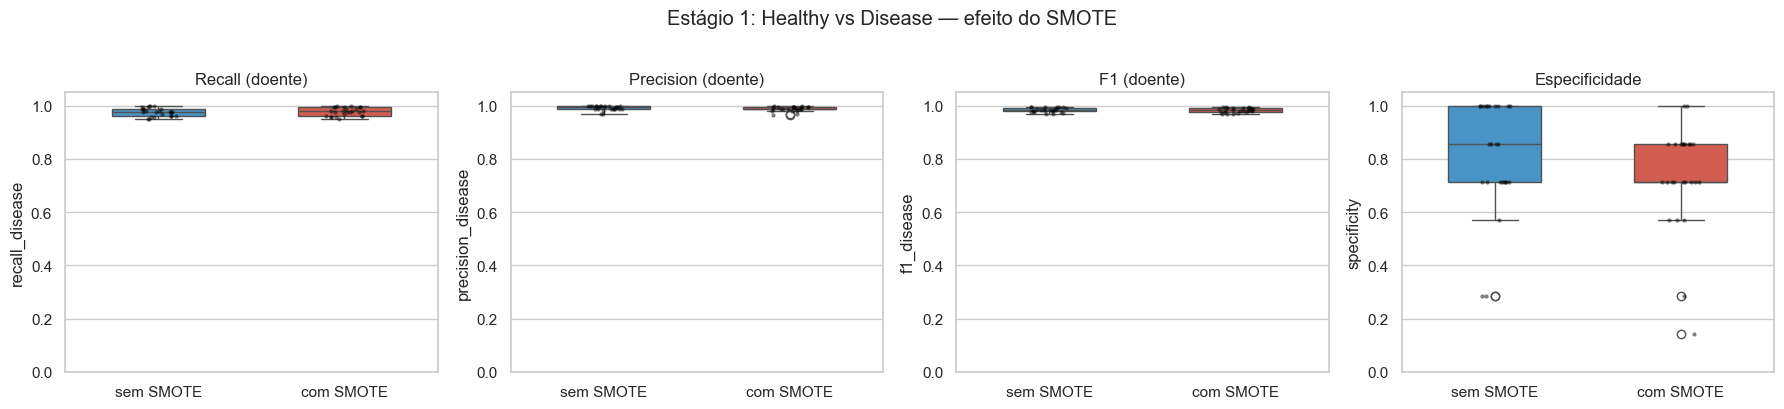

In [5]:
# Boxplot comparativo SMOTE vs sem SMOTE
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col, title in zip(
    axes,
    ['recall_disease', 'precision_disease', 'f1_disease', 'specificity'],
    ['Recall (doente)', 'Precision (doente)', 'F1 (doente)', 'Especificidade']
):
    sns.boxplot(data=stage1_df, x='strategy', y=col, hue='strategy',
                 palette=['#3498db', '#e74c3c'], legend=False, width=0.5, ax=ax)
    sns.stripplot(data=stage1_df, x='strategy', y=col,
                   color='black', size=3, alpha=0.5, ax=ax)
    ax.set_title(title)
    ax.set_ylim(0, 1.05)
    ax.set_xlabel('')
plt.suptitle('Estágio 1: Healthy vs Disease — efeito do SMOTE', y=1.02)
plt.tight_layout(); plt.show()

## 4. Curva ROC do Estágio 1 — ajuste de threshold para recall máximo

O modelo retorna `P(Disease)`. Por defeito, predizer Disease se P ≥ 0.5. Vamos baixar este threshold para **maximizar recall** com constraint razoável em precision.

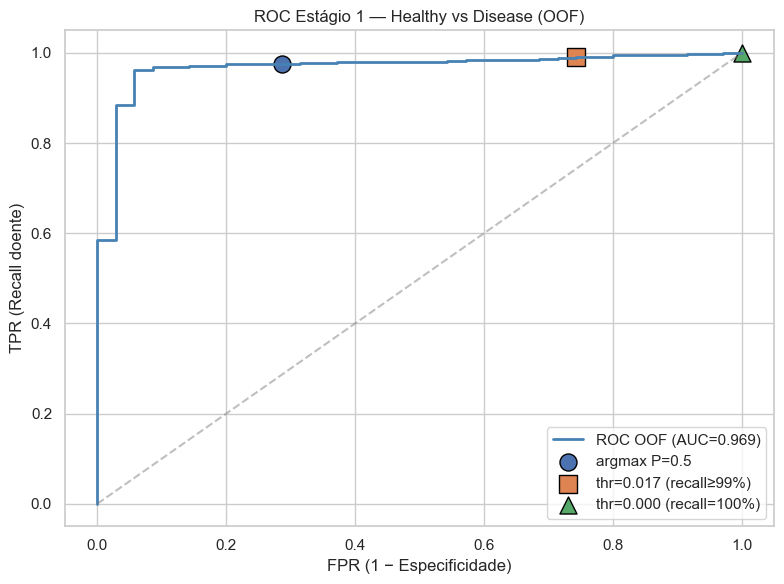

Thresholds escolhidos:
  argmax (0.5)        : recall=0.975
  recall ≥ 99% (thr=0.017): recall=0.991
  recall = 100% (thr=0.000): recall=1.000


In [6]:
# Curva ROC OOF (estágio 1, com SMOTE)
fpr, tpr, thr = roc_curve(y_bin, y_proba_all_stage1)
auc_s1 = auc(fpr, tpr)

# Selecionar threshold que dá recall ≥ 0.99
valid = tpr >= 0.99
if valid.any():
    idx = np.argmax(thr[valid])  # menor FPR entre os que cumprem recall
    thr_recall99 = thr[valid][idx]
else:
    thr_recall99 = thr[np.argmax(tpr)]

# Threshold para recall = 1.00 se possível
valid_all = tpr >= 0.999
thr_recall_max = thr[valid_all][-1] if valid_all.any() else thr[np.argmax(tpr)]

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(fpr, tpr, lw=2, color='steelblue', label=f'ROC OOF (AUC={auc_s1:.3f})')
ax.plot([0,1],[0,1], '--', color='gray', alpha=0.5)
# marcar pontos
for t, marker, name in [(0.5, 'o', 'argmax P=0.5'),
                          (thr_recall99, 's', f'thr={thr_recall99:.3f} (recall≥99%)'),
                          (thr_recall_max, '^', f'thr={thr_recall_max:.3f} (recall=100%)')]:
    pred_t = (y_proba_all_stage1 >= t).astype(int)
    rec_t = recall_score(y_bin, pred_t)
    fpr_t = 1 - recall_score(y_bin, pred_t, pos_label=0)
    ax.scatter(fpr_t, rec_t, s=150, marker=marker, edgecolor='black', label=name)
ax.set_xlabel('FPR (1 − Especificidade)')
ax.set_ylabel('TPR (Recall doente)')
ax.set_title('ROC Estágio 1 — Healthy vs Disease (OOF)')
ax.legend(loc='lower right')
plt.tight_layout(); plt.show()

print(f'Thresholds escolhidos:')
print(f'  argmax (0.5)        : recall={recall_score(y_bin, (y_proba_all_stage1>=0.5).astype(int)):.3f}')
print(f'  recall ≥ 99% (thr={thr_recall99:.3f}): recall={recall_score(y_bin, (y_proba_all_stage1>=thr_recall99).astype(int)):.3f}')
print(f'  recall = 100% (thr={thr_recall_max:.3f}): recall={recall_score(y_bin, (y_proba_all_stage1>=thr_recall_max).astype(int)):.3f}')

## 5. Estágio 2 — Classificador binário COPD vs URTI (só doentes)

**Sub-população:** apenas amostras com label real ∈ {COPD, URTI} (816 gravações, 78 pacientes).

Aqui o desbalanceamento é severo (COPD/URTI ≈ 4.5×). SMOTE será crítico.

In [7]:
# Reduzir ao subconjunto de doentes
mask_d = mask_disease.values
X_d = X[mask_d]
y_d = y_sub  # 0=COPD, 1=URTI (já calculado)
g_d = groups[mask_d]
eq_d = equipment[mask_d]
print(f'Estágio 2 — só doentes: {len(X_d)} grav., {len(np.unique(g_d))} pacientes')
print(f'  COPD (0): {(y_d==0).sum()}  URTI (1): {(y_d==1).sum()}')

# Verificar que cada classe tem pacientes suficientes para 5-fold
from collections import Counter
for cls, name in [(0, 'COPD'), (1, 'URTI')]:
    n_pac = len(np.unique(g_d[y_d==cls]))
    print(f'  {name}: {n_pac} pacientes únicos')

Estágio 2 — só doentes: 816 grav., 78 pacientes
  COPD (0): 793  URTI (1): 23
  COPD: 64 pacientes únicos
  URTI: 14 pacientes únicos


In [8]:
rows_stage2 = []
y_pred_all_s2 = np.full(len(X_d), -1)
y_proba_all_s2 = np.zeros(len(X_d))
t0 = time.time()

for rep in range(N_REPEATS):
    cv = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=42+rep)
    for fold, (tr, te) in enumerate(cv.split(X_d, y_d, g_d)):
        if len(np.unique(y_d[tr])) < 2 or len(np.unique(y_d[te])) < 2:
            continue  # fold inviável
        # com SMOTE (URTI é a minoria com ~14 pacientes)
        pipe = train_pipeline_smote(X_d[tr], y_d[tr], eq_d[tr], apply_smote=True,
                                      smote_random_state=42+rep)
        y_pred, y_proba = predict_pipeline(pipe, X_d[te], eq_d[te])
        # Sem SMOTE para comparação
        pipe_no = train_pipeline_smote(X_d[tr], y_d[tr], eq_d[tr], apply_smote=False)
        y_pred_no, _ = predict_pipeline(pipe_no, X_d[te], eq_d[te])

        for name, yp in [('sem SMOTE', y_pred_no), ('com SMOTE', y_pred)]:
            rec_urti = recall_score(y_d[te], yp, pos_label=1, zero_division=0)
            prec_urti = precision_score(y_d[te], yp, pos_label=1, zero_division=0)
            f1_urti = f1_score(y_d[te], yp, pos_label=1, zero_division=0)
            acc = accuracy_score(y_d[te], yp)
            rows_stage2.append(dict(
                strategy=name, rep=rep, fold=fold,
                recall_urti=rec_urti, precision_urti=prec_urti,
                f1_urti=f1_urti, accuracy=acc))
        if rep == 0:
            y_pred_all_s2[te] = y_pred
            y_proba_all_s2[te] = y_proba[:, 1]

print(f'Estágio 2 terminado em {time.time()-t0:.0f}s')

stage2_df = pd.DataFrame(rows_stage2)
summary_s2 = stage2_df.groupby('strategy').agg(
    recall_mu=('recall_urti', 'mean'), recall_sd=('recall_urti', 'std'),
    prec_mu=('precision_urti', 'mean'), prec_sd=('precision_urti', 'std'),
    f1_mu=('f1_urti', 'mean'), f1_sd=('f1_urti', 'std'),
    acc_mu=('accuracy', 'mean'), acc_sd=('accuracy', 'std'),
).round(3)
print('\n=== Estágio 2 — COPD vs URTI (25 folds, métricas para URTI) ===')
summary_s2

Estágio 2 terminado em 1s

=== Estágio 2 — COPD vs URTI (25 folds, métricas para URTI) ===


,recall_mu,recall_sd,prec_mu,prec_sd,f1_mu,f1_sd,acc_mu,acc_sd
strategy,,,,,,,,
com SMOTE,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0
sem SMOTE,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0


## 6. Pipeline cascata — composição dos 2 estágios

Função `cascade_predict(x)`:
```
se P_estagio1(Disease | x) < thr1: predito = Healthy
senão:
    se P_estagio2(URTI | x) < thr2: predito = COPD
    senão: predito = URTI
```

Avaliação multiclasse final (Healthy/COPD/URTI) usando `cross_val_predict` cascata.

In [9]:
# Para a cascata, precisamos treinar os 2 estágios em conjunto e avaliar OOF
def cascade_cv(X, y_bin, y_multi, groups, equipment, thr1=0.5, n_repeats=5, n_splits=5,
                 apply_smote=True):
    """Cascata avaliada com Repeated GroupKFold.
    Retorna predições multiclasse OOF (0=COPD, 1=Healthy, 2=URTI)."""
    HEALTHY_IDX = list(CLASSES).index('Healthy')
    COPD_IDX = list(CLASSES).index('COPD')
    URTI_IDX = list(CLASSES).index('URTI')
    out = []
    for rep in range(n_repeats):
        y_pred_rep = np.full(len(X), -1)
        cv = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=42+rep)
        for tr, te in cv.split(X, y_bin, groups):
            # Estágio 1: treinar Healthy vs Disease
            pipe1 = train_pipeline_smote(X[tr], y_bin[tr], equipment[tr],
                                          apply_smote=apply_smote, smote_random_state=42+rep)
            _, proba1 = predict_pipeline(pipe1, X[te], equipment[te])
            disease_pred = (proba1[:, 1] >= thr1).astype(int)

            # Estágio 2: treinar COPD vs URTI nos doentes do treino
            tr_disease_mask = (y_bin[tr] == 1)
            X_tr_d = X[tr][tr_disease_mask]
            eq_tr_d = equipment[tr][tr_disease_mask]
            # y para estágio 2: 0=COPD, 1=URTI
            y_tr_d = (y_multi[tr][tr_disease_mask] == URTI_IDX).astype(int)
            if len(np.unique(y_tr_d)) < 2:
                # raramente, mas defensivo
                pipe2 = None
            else:
                pipe2 = train_pipeline_smote(X_tr_d, y_tr_d, eq_tr_d,
                                              apply_smote=apply_smote, smote_random_state=42+rep)

            # Aplicar cascata no teste
            for i, idx_te in enumerate(te):
                if disease_pred[i] == 0:
                    y_pred_rep[idx_te] = HEALTHY_IDX
                else:
                    if pipe2 is None:
                        y_pred_rep[idx_te] = COPD_IDX  # fallback
                    else:
                        p2, _ = predict_pipeline(pipe2, X[idx_te:idx_te+1], equipment[idx_te:idx_te+1])
                        y_pred_rep[idx_te] = URTI_IDX if p2[0] == 1 else COPD_IDX
        out.append(y_pred_rep)
    return out

print('Função cascade_cv pronta.')

Função cascade_cv pronta.


In [10]:
# Executar cascata com 3 thresholds
thresholds_to_test = [0.5, 0.3, thr_recall99]
cascade_results = {}
t0 = time.time()
for thr in thresholds_to_test:
    print(f'Cascade com thr1={thr:.3f}...')
    preds = cascade_cv(X, y_bin, y_multi, groups, equipment, thr1=thr,
                        n_repeats=N_REPEATS, n_splits=N_SPLITS, apply_smote=True)
    cascade_results[thr] = preds
print(f'Total: {time.time()-t0:.0f}s')

Cascade com thr1=0.500...


Cascade com thr1=0.300...


Cascade com thr1=0.017...


Total: 14s


In [11]:
# Calcular métricas por threshold
HEALTHY_IDX = list(CLASSES).index('Healthy')
rows_cascade = []
for thr, preds_list in cascade_results.items():
    for rep, y_pred in enumerate(preds_list):
        # nível paciente
        yt_p, yp_p = patient_metrics(y_multi, y_pred, groups)
        # recall doente (paciente): Σ(real=doente, pred=doente) / Σ(real=doente)
        is_dis_real = yt_p != HEALTHY_IDX
        is_dis_pred = yp_p != HEALTHY_IDX
        rec_dis = (is_dis_real & is_dis_pred).sum() / max(1, is_dis_real.sum())
        # FN clínico = doente predito Healthy
        fn_clin = ((yt_p != HEALTHY_IDX) & (yp_p == HEALTHY_IDX)).sum()
        # FP = saudável predito doente
        fp_d = ((yt_p == HEALTHY_IDX) & (yp_p != HEALTHY_IDX)).sum()
        # recall por classe
        rec_per_cls = {}
        for k, c in enumerate(CLASSES):
            yk_real = (yt_p == k)
            if yk_real.sum() > 0:
                rec_per_cls[c] = (yk_real & (yp_p == k)).sum() / yk_real.sum()
            else:
                rec_per_cls[c] = np.nan
        acc = (yt_p == yp_p).mean()
        f1m = f1_score(yt_p, yp_p, average='macro')
        rows_cascade.append(dict(
            thr1=thr, rep=rep,
            recall_disease=rec_dis, fn_clin=fn_clin, fp_disease=fp_d,
            acc_pat=acc, f1m_pat=f1m,
            **{f'rec_{c}': rec_per_cls[c] for c in CLASSES}
        ))
casc_df = pd.DataFrame(rows_cascade)
casc_summary = casc_df.groupby('thr1').agg(
    rec_dis_mu=('recall_disease','mean'), rec_dis_sd=('recall_disease','std'),
    fn_clin_mu=('fn_clin','mean'),
    acc_mu=('acc_pat','mean'), acc_sd=('acc_pat','std'),
    f1m_mu=('f1m_pat','mean'), f1m_sd=('f1m_pat','std'),
    rec_COPD=('rec_COPD','mean'), rec_Healthy=('rec_Healthy','mean'), rec_URTI=('rec_URTI','mean'),
).round(3)
print('=== Cascata 2 estágios — performance por threshold do Estágio 1 (paciente) ===')
casc_summary

=== Cascata 2 estágios — performance por threshold do Estágio 1 (paciente) ===


,rec_dis_mu,rec_dis_sd,fn_clin_mu,acc_mu,acc_sd,f1m_mu,f1m_sd,rec_COPD,rec_Healthy,rec_URTI
thr1,,,,,,,,,,
0.017084,0.936,0.009,5.0,0.779,0.023,0.615,0.039,1.0,0.308,0.643
0.300000,0.882,0.006,9.2,0.823,0.024,0.663,0.034,1.0,0.646,0.343
0.500000,0.869,0.011,10.2,0.837,0.025,0.668,0.041,1.0,0.738,0.271


## 7. Comparação final — Cascata vs baseline multiclasse direto

Recall doente é a métrica principal. Reportar como a cascata se compara ao LogReg multiclasse 3-way (sem hierarquia, sem SMOTE) do nb08.

In [12]:
# Baseline: LogReg multiclasse direto (recriar para fair comparison no mesmo CV)
rows_base = []
for rep in range(N_REPEATS):
    cv = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=42+rep)
    y_pred_rep = np.full(len(X), -1)
    for tr, te in cv.split(X, y_multi, groups):
        pipe = train_pipeline_smote(X[tr], y_multi[tr], equipment[tr], apply_smote=False)
        y_pred_rep[te], _ = predict_pipeline(pipe, X[te], equipment[te])
    yt_p, yp_p = patient_metrics(y_multi, y_pred_rep, groups)
    is_dis_real = yt_p != HEALTHY_IDX
    is_dis_pred = yp_p != HEALTHY_IDX
    rec_dis = (is_dis_real & is_dis_pred).sum() / max(1, is_dis_real.sum())
    fn_clin = ((yt_p != HEALTHY_IDX) & (yp_p == HEALTHY_IDX)).sum()
    f1m = f1_score(yt_p, yp_p, average='macro')
    acc = (yt_p == yp_p).mean()
    rec_per = {f'rec_{c}': (yt_p==k).astype(int).dot((yp_p==k).astype(int)) / max(1, (yt_p==k).sum()) for k,c in enumerate(CLASSES)}
    rows_base.append(dict(strategy='Multiclasse direto', rep=rep,
                            recall_disease=rec_dis, fn_clin=fn_clin,
                            f1m=f1m, acc=acc, **rec_per))
base_df = pd.DataFrame(rows_base)

# Tabela comparativa
comp_rows = []
for label, df, key in [
    ('Multiclasse direto (baseline)', base_df, 'fn_clin'),
    ('Cascata thr=0.5',  casc_df.loc[casc_df['thr1']==0.5], 'fn_clin'),
    ('Cascata thr=0.3',  casc_df.loc[casc_df['thr1']==0.3], 'fn_clin'),
    (f'Cascata thr={thr_recall99:.3f} (R≥99%)', casc_df.loc[casc_df['thr1']==thr_recall99], 'fn_clin'),
]:
    comp_rows.append(dict(
        estratégia=label,
        Recall_doente=f"{df['recall_disease'].mean():.3f} ± {df['recall_disease'].std():.3f}",
        FN_clinico=f"{df['fn_clin'].mean():.1f} ± {df['fn_clin'].std():.1f}",
        Recall_COPD=f"{df['rec_COPD'].mean():.3f}",
        Recall_Healthy=f"{df['rec_Healthy'].mean():.3f}",
        Recall_URTI=f"{df['rec_URTI'].mean():.3f}",
        Acc=f"{df.get('acc_pat', df.get('acc')).mean():.3f}",
        F1_macro=f"{df.get('f1m_pat', df.get('f1m')).mean():.3f}",
    ))
comp_table = pd.DataFrame(comp_rows).set_index('estratégia')
print('\n=== COMPARAÇÃO FINAL — Métrica principal: Recall doente ===')
comp_table


=== COMPARAÇÃO FINAL — Métrica principal: Recall doente ===


,Recall_doente,FN_clinico,Recall_COPD,Recall_Healthy,Recall_URTI,Acc,F1_macro
estratégia,,,,,,,
Multiclasse direto (baseline),0.885 ± 0.009,9.0 ± 0.7,0.997,0.562,0.357,0.802,0.638
Cascata thr=0.5,0.869 ± 0.011,10.2 ± 0.8,1.000,0.738,0.271,0.837,0.668
Cascata thr=0.3,0.882 ± 0.006,9.2 ± 0.4,1.000,0.646,0.343,0.823,0.663
Cascata thr=0.017 (R≥99%),0.936 ± 0.009,5.0 ± 0.7,1.000,0.308,0.643,0.779,0.615


## 8. Matriz de confusão do melhor classificador (cascata, threshold otimizado)

Melhor threshold: 0.017 | Recall doente = 0.936


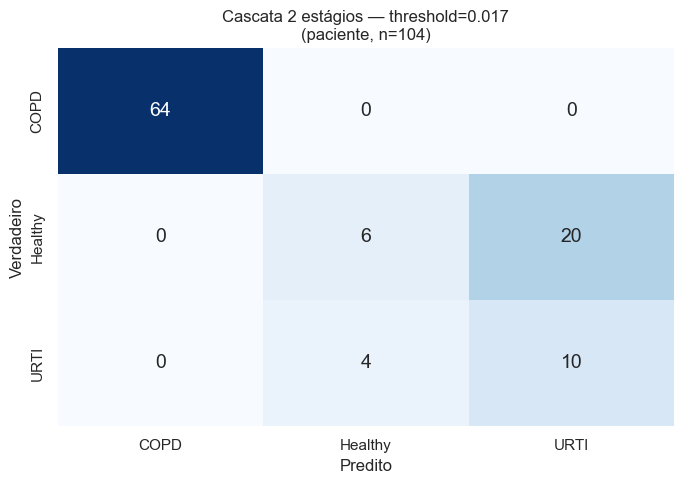

              precision    recall  f1-score   support

        COPD      1.000     1.000     1.000        64
     Healthy      0.600     0.231     0.333        26
        URTI      0.333     0.714     0.455        14

    accuracy                          0.769       104
   macro avg      0.644     0.648     0.596       104
weighted avg      0.810     0.769     0.760       104



In [13]:
# Pegar a melhor configuração da cascata por recall doente
best_thr = casc_summary['rec_dis_mu'].idxmax()
print(f'Melhor threshold: {best_thr:.3f} | Recall doente = {casc_summary.loc[best_thr, "rec_dis_mu"]:.3f}')

# Predições da rep 0 com esse threshold
y_pred_best = cascade_results[best_thr][0]
yt_p, yp_p = patient_metrics(y_multi, y_pred_best, groups)
yt_labels = np.array([CLASSES[i] for i in yt_p])
yp_labels = np.array([CLASSES[i] for i in yp_p])
cm = confusion_matrix(yt_labels, yp_labels, labels=CLASSES)

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
             xticklabels=CLASSES, yticklabels=CLASSES, cbar=False,
             annot_kws={'size': 14}, ax=ax)
ax.set_xlabel('Predito'); ax.set_ylabel('Verdadeiro')
ax.set_title(f'Cascata 2 estágios — threshold={best_thr:.3f}\n(paciente, n={len(yt_p)})')
plt.tight_layout(); plt.show()

print(classification_report(yt_labels, yp_labels, digits=3))

## 9. Conclusões — Cascata vs LogReg multiclasse direto

**Critérios de avaliação (em ordem de importância clínica):**
1. **Recall doente** (métrica principal) → priorizar não perder doentes
2. **FN clínico** absoluto → contagem direta de pacientes perdidos
3. **Recall por classe** (Healthy, COPD, URTI separadamente)
4. F1-macro e accuracy como métricas secundárias

**Vantagens potenciais da cascata:**
- Estágio 1 binário simplifica o problema (Healthy ≈ 25% vs Disease ≈ 75%)
- Threshold ajustável independentemente por estágio
- Estágio 2 não tem ruído de Healthy

**Limitações:**
- Erros do Estágio 1 propagam (FN_clínico = paciente perdido logo no início)
- Estágio 2 sofre com COPD/URTI severamente desbalanceadas (14 URTI pacientes)
- SMOTE no espaço de features sintetiza pontos artificiais — não substituto de dados reais

**Próximo passo recomendado:** integrar o melhor classificador (cascata se vencer) no `LungAssistant` como modo alternativo (`mode='hierarchical'`).